# SpecSynth AI — Notebook 01: Material Data Anomaly Detection

**Method:** Isolation Forest  
**Dataset:** SpecSynth Master Database v1.5.0  
**Purpose:** Find material records with unusual combinations of thickness, thermal resistance and thermal conductivity that may deserve a closer review.

This is a first screening tool. A flagged record is **not automatically wrong**. It may be unusual because it is a specialist product or a valid material variation.

### Important choices
- Use the existing `recommended_split` values.
- Fit the model using training records only.
- Score eligible records across the available splits.
- Use records with all three selected properties present; do not fill missing physical values with invented estimates.
- Keep the original dataset unchanged.
- Treat the chosen anomaly percentage as a review setting, not as a known error rate.


## 1. Load the dataset and set up output folders

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=FutureWarning)

DATASET_RELATIVE = Path(
    "04_Product_Dataset",
    "10_Master_Database",
    "SpecSynth_Master_Database_v1.0",
    "source_data",
    "v1.5.0"
)

def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        csv_candidate = candidate / DATASET_RELATIVE / "ml" / "SpecSynth_ML_variants_v1.5.0.csv"
        if csv_candidate.exists():
            return candidate
    raise FileNotFoundError("Could not find the SpecSynth_AI project root.")

PROJECT_ROOT = find_project_root(Path.cwd())
ML_ROOT = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine"

CSV_PATH = PROJECT_ROOT / DATASET_RELATIVE / "ml" / "SpecSynth_ML_variants_v1.5.0.csv"
MODEL_DIR = ML_ROOT / "03_Models" / "anomaly_detection"
REPORT_DIR = ML_ROOT / "04_Evaluation" / "reports"
FIGURE_DIR = ML_ROOT / "04_Evaluation" / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV_PATH)

print("Project root:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("Output folders are ready.")

Project root: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI
Dataset shape: (1941, 47)
Output folders are ready.


### Outcome and conclusion

The dataset was loaded successfully. It contains **1,941 records and 47 columns**. The notebook also found the project folders and prepared locations for saving the trained model and reports.

This confirms that the anomaly-detection experiment is using the intended SpecSynth product dataset. At this stage, no records have been changed; the notebook is only reading the data and preparing the analysis.

## 2. Choose the properties for the first screening

We will start with three physical properties that are available for most records:
- **Thickness (mm):** how thick the product is.
- **Thermal resistance (m²K/W):** how strongly the product resists heat flow.
- **Thermal conductivity (W/m·K):** how easily heat passes through the material.

These values are related, so this first model mainly looks for unusual combinations among them. It is not a complete check of every product specification.

In [2]:
FEATURES = [
    "thickness_mm",
    "thermal_resistance_m2K_W",
    "thermal_conductivity_W_mK"
]

TARGET_COLUMNS = [
    "target_thermal_conductivity_W_mK",
    "target_density_kg_m3",
    "target_specific_heat_J_kgK",
    "target_gwp_a1_a3_kgco2e_m2",
    "target_price_per_m2"
]

required_columns = FEATURES + [
    "record_id", "product_id", "variant_id",
    "material_family", "material_category_group",
    "manufacturer", "data_status", "recommended_split"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

feature_coverage = pd.DataFrame({
    "available_records": df[FEATURES].notna().sum(),
    "missing_records": df[FEATURES].isna().sum(),
    "coverage_percent": (df[FEATURES].notna().mean() * 100).round(1)
})
display(feature_coverage)

print("Split counts:")
display(df["recommended_split"].value_counts(dropna=False).to_frame("records"))

,available_records,missing_records,coverage_percent
thickness_mm,1926,15,99.2
thermal_resistance_m2K_W,1820,121,93.8
thermal_conductivity_W_mK,1781,160,91.8


Split counts:


,records
recommended_split,
train,1621
validation,186
test,134


### Outcome and conclusion

The three selected properties are available for most records:

- Thickness: **1,926 records (99.2%)**
- Thermal resistance: **1,820 records (93.8%)**
- Thermal conductivity: **1,781 records (91.8%)**

Thermal conductivity has the lowest coverage of the three, but it is still available for most of the dataset. The existing split contains 1,621 training, 186 validation and 134 test records.

These results show that the selected properties are suitable for an initial screening experiment. We will keep the existing split so related product records remain separated in the same way as the dataset's original design.

## 3. Prepare eligible records

For this first version, we will only use records that have all three selected values. This avoids replacing missing material properties with averages, which could make some records look more ordinary than they really are.

We also keep the original product identifiers and verification status so that flagged records can be checked later.

In [3]:
analysis_df = df[required_columns].copy()

for col in FEATURES:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")

eligible = analysis_df[FEATURES].notna().all(axis=1)
analysis_df = analysis_df.loc[eligible].copy()

# Remove physically impossible or unusable values from this screening set.
# These are not deleted from the source dataset; they are simply not scored.
positive_values = (
    (analysis_df["thickness_mm"] > 0)
    & (analysis_df["thermal_resistance_m2K_W"] > 0)
    & (analysis_df["thermal_conductivity_W_mK"] > 0)
)
analysis_df = analysis_df.loc[positive_values].copy()

print("Eligible complete records:", len(analysis_df))
print("Records excluded because a selected value was missing or non-positive:",
      len(df) - len(analysis_df))
print("\nEligible records by split:")
display(analysis_df["recommended_split"].value_counts().to_frame("records"))

if analysis_df["recommended_split"].eq("train").sum() < 30:
    raise ValueError("Not enough eligible training records for this first model.")

Eligible complete records: 1761
Records excluded because a selected value was missing or non-positive: 180

Eligible records by split:


,records
recommended_split,
train,1477
validation,173
test,111


### Outcome and conclusion

After keeping only records with all three valid values, **1,761 records** remained. Another **180 records** were excluded from this experiment because at least one selected value was missing or not positive.

The eligible records are divided into:
- Training: **1,477**
- Validation: **173**
- Testing: **111**

The excluded records have not been removed from the master dataset. They are simply not suitable for this particular model because it needs all three inputs. This is important: the anomaly results apply to the 1,761 eligible records, not to every record in the original dataset.

## 4. Review the selected properties before modelling

,count,mean,std,min,25%,50%,75%,max
thickness_mm,1761.0,137.336173,85.123625,6.0000,70.000,120.000,190.000,528.00
thermal_resistance_m2K_W,1761.0,4.135576,2.514834,0.0353,2.150,3.850,5.800,12.90
thermal_conductivity_W_mK,1761.0,0.038563,0.029851,0.0190,0.031,0.034,0.037,0.35


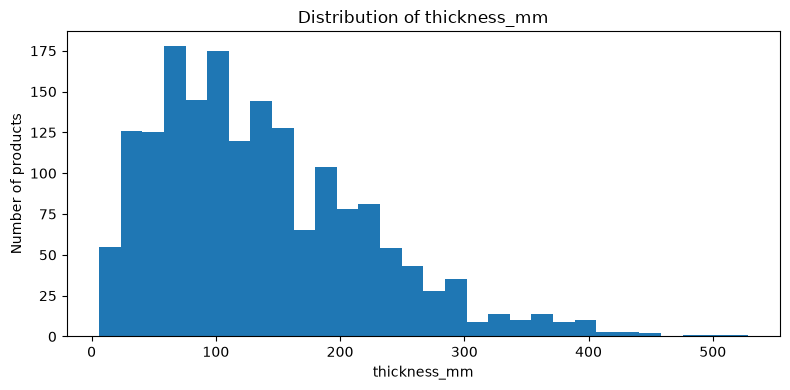

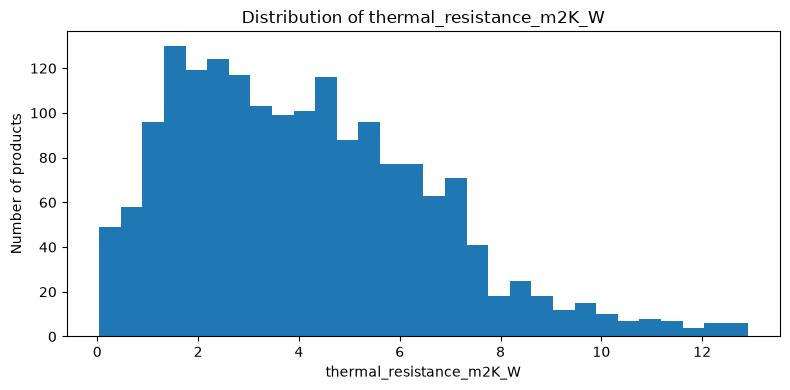

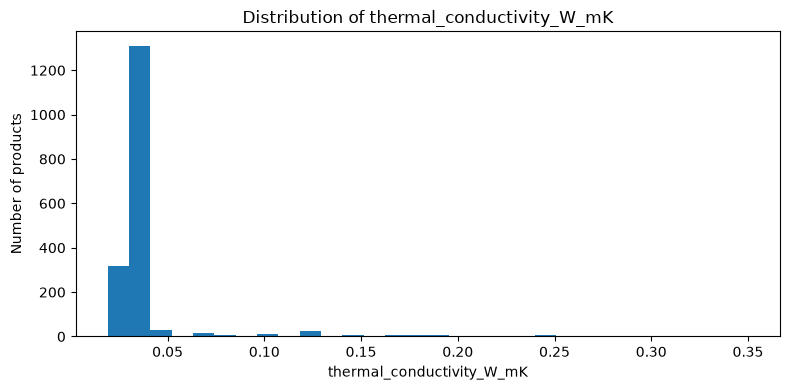

In [4]:
display(analysis_df[FEATURES].describe().T)

for feature in FEATURES:
    plt.figure(figsize=(8, 4))
    plt.hist(analysis_df[feature], bins=30)
    plt.xlabel(feature)
    plt.ylabel("Number of products")
    plt.title(f"Distribution of {feature}")
    plt.tight_layout()
    plt.show()

### Outcome and conclusion

The charts and summary statistics show that the eligible records cover a wide range of product thicknesses and thermal properties.

For example, thickness ranges from **6 mm to 528 mm**, while thermal conductivity ranges from **0.019 to 0.35 W/mK**. This wide range is expected because the dataset contains different construction product types, not only insulation.

Some values sit far away from the main concentration of values. That does not automatically make them incorrect. A thick wall product and a thin board product naturally have different characteristics. The model therefore needs to be interpreted with material type and product documentation in mind.

**What this tells us:** These charts show the range of values in the records being checked. A long tail or a small number of very different values is not necessarily an error; it gives us areas to review after the model runs.

## 5. Train Isolation Forest on training records

Isolation Forest looks for records that are easier to separate from the rest of the data. Those records receive an anomaly flag.

We set `contamination` to 0.03 for this first review, meaning the model is configured to flag approximately 3% of the training records as unusual. This is a starting setting, not a claim that 3% of the dataset is incorrect.

The scaler and model are placed in one pipeline so the same preparation is applied consistently when scoring other records.

In [5]:
CONTAMINATION = 0.03
RANDOM_STATE = 42

train_mask = analysis_df["recommended_split"].eq("train")
X_train = analysis_df.loc[train_mask, FEATURES]

model = Pipeline(steps=[
    ("scaler", RobustScaler()),
    ("isolation_forest", IsolationForest(
        n_estimators=300,
        contamination=CONTAMINATION,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train)

print("Model trained.")
print("Training records:", len(X_train))
print("Features used:", FEATURES)
print("Configured contamination:", CONTAMINATION)

Model trained.
Training records: 1477
Features used: ['thickness_mm', 'thermal_resistance_m2K_W', 'thermal_conductivity_W_mK']
Configured contamination: 0.03


### Outcome and conclusion

The Isolation Forest pipeline trained successfully using the **1,477 training records** and the three selected properties.

The model uses RobustScaler to reduce the influence of very large values when scaling the inputs, followed by Isolation Forest to identify records that are less typical. The configured contamination value is **3%**, which is a setting for this experiment—not a claim that 3% of the dataset contains errors.

The model was fitted only on the training records. This helps prevent the validation and test records from influencing what the model learns.

## 6. Score the eligible records

The model is fitted only on the training portion. We now apply it to all eligible records so we can inspect training, validation and test results using the same fitted model.

`-1` means the model flags the record as unusual. `1` means it does not flag the record.

In [6]:
X_all = analysis_df[FEATURES]

predictions = model.predict(X_all)
anomaly_scores = model.decision_function(X_all)

results = analysis_df.copy()
results["anomaly_label"] = predictions
results["anomaly_status"] = np.where(
    results["anomaly_label"] == -1,
    "REVIEW",
    "NOT_FLAGGED"
)
results["anomaly_score"] = anomaly_scores

print("Scoring completed.")
display(results["anomaly_status"].value_counts().to_frame("records"))

split_summary = pd.crosstab(
    results["recommended_split"],
    results["anomaly_status"],
    margins=True
)
display(split_summary)

Scoring completed.


,records
anomaly_status,
NOT_FLAGGED,1696
REVIEW,65


anomaly_status,NOT_FLAGGED,REVIEW,All
recommended_split,,,
test,97,14,111
train,1432,45,1477
validation,167,6,173
All,1696,65,1761


### Outcome and conclusion

The model scored all **1,761 eligible records** and produced:

- **1,696 records (96.31%)** not flagged.
- **65 records (3.69%)** flagged for review.

The flags across the existing data splits are:
- Training: 45 flagged out of 1,477.
- Validation: 6 flagged out of 173.
- Testing: 14 flagged out of 111.

A `REVIEW` result means that the combination of selected values looks unusual compared with the patterns learned by the model. It does not mean that the product is wrong. The records flagged in the test group should also be reviewed as part of understanding how the model behaves on held-out groups.

## 7. Visualise the results

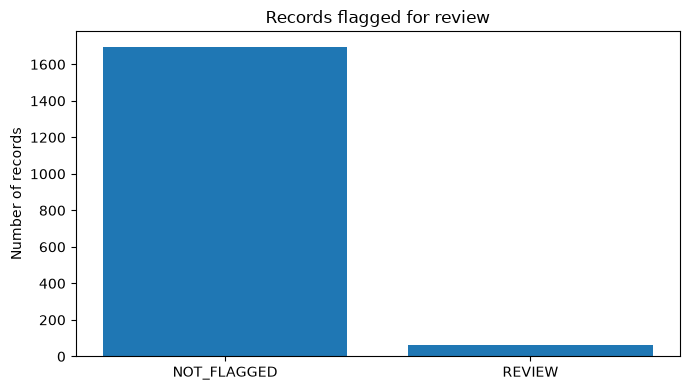

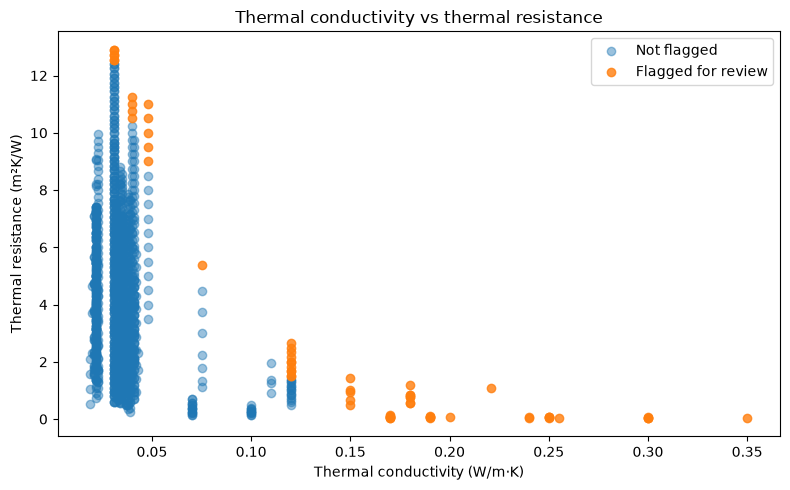

In [7]:
status_counts = results["anomaly_status"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(status_counts.index, status_counts.values)
plt.ylabel("Number of records")
plt.title("Records flagged for review")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
normal = results[results["anomaly_status"] == "NOT_FLAGGED"]
flagged = results[results["anomaly_status"] == "REVIEW"]

plt.scatter(
    normal["thermal_conductivity_W_mK"],
    normal["thermal_resistance_m2K_W"],
    alpha=0.45,
    label="Not flagged"
)
plt.scatter(
    flagged["thermal_conductivity_W_mK"],
    flagged["thermal_resistance_m2K_W"],
    alpha=0.8,
    label="Flagged for review"
)
plt.xlabel("Thermal conductivity (W/m·K)")
plt.ylabel("Thermal resistance (m²K/W)")
plt.title("Thermal conductivity vs thermal resistance")
plt.legend()
plt.tight_layout()
plt.show()

### Outcome and conclusion

The charts show the balance between records that were flagged and those that were not. They also show how the selected thermal properties relate to one another.

The flagged points are records that the model considers less typical. Their position in the chart can help us see why they stand out, but the chart alone cannot confirm a data error.

Thickness, thermal resistance and thermal conductivity are physically related. Because of this relationship, an unusual combination may deserve a closer check against the product datasheet. It should not be corrected or rejected without supporting evidence.

**What this tells us:** The highlighted points are the records the model considers less typical. They should be checked against their product documents before deciding whether anything needs correcting.

## 8. Inspect the records flagged for review

In [8]:
review_columns = [
    "record_id",
    "product_id",
    "variant_id",
    "material_category_group",
    "material_family",
    "manufacturer",
    "data_status",
    "recommended_split",
    *FEATURES,
    "anomaly_score"
]

flagged_records = (
    results.loc[results["anomaly_status"] == "REVIEW", review_columns]
    .sort_values("anomaly_score")
)

print("Records flagged for review:", len(flagged_records))
display(flagged_records.head(30))

Records flagged for review: 65


,record_id,product_id,variant_id,material_category_group,material_family,manufacturer,data_status,recommended_split,thickness_mm,thermal_resistance_m2K_W,thermal_conductivity_W_mK,anomaly_score
23,ML_AGTECNO3_TECNOARCILLA_24_240MM,AGTECNO3_TECNOARCILLA_24,AGTECNO3_TECNOARCILLA_24_240MM,B_masonry,fired_clay_masonry,AG Tecno-3,VERIFIED,train,240.0,1.0700,0.221,-0.083236
1506,ML_KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR_12_5MM,KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR,KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR_12_5MM,E_boards,cement_board,Knauf AQUAPANEL GmbH & Co. KG,VERIFIED,train,12.5,0.0357,0.350,-0.074489
1887,ML_SGUK_GLASROC_F_MULTIBOARD_12_5MM,SGUK_GLASROC_F_MULTIBOARD,SGUK_GLASROC_F_MULTIBOARD_12_5MM,E_boards,gypsum_specialist_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0420,0.300,-0.070633
1888,ML_SGUK_GLASROC_H_TILEBACKER_12_5MM,SGUK_GLASROC_H_TILEBACKER,SGUK_GLASROC_H_TILEBACKER_12_5MM,E_boards,gypsum_specialist_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0420,0.300,-0.070633
1886,ML_SGUK_GLASROC_F_FIRECASE_20MM,SGUK_GLASROC_F_FIRECASE,SGUK_GLASROC_F_FIRECASE_20MM,E_boards,gypsum_specialist_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,test,20.0,0.0670,0.300,-0.068000
1885,ML_SGUK_GLASROC_F_FIRECASE_15MM,SGUK_GLASROC_F_FIRECASE,SGUK_GLASROC_F_FIRECASE_15MM,E_boards,gypsum_specialist_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,test,15.0,0.0500,0.300,-0.066763
1502,ML_HH_UK_CELCON_BLOCK_HIGH_STRENGTH_215MM,HH_UK_CELCON_BLOCK_HIGH_STRENGTH,HH_UK_CELCON_BLOCK_HIGH_STRENGTH_215MM,B_masonry,AAC,H+H UK Ltd,PARTIALLY_VERIFIED,train,215.0,1.1940,0.180,-0.055728
1889,ML_SGUK_GLASROC_X_SHEATHING_BOARD_12_5MM,SGUK_GLASROC_X_SHEATHING_BOARD,SGUK_GLASROC_X_SHEATHING_BOARD_12_5MM,E_boards,gypsum_specialist_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0490,0.255,-0.054803
1875,ML_SGUK_GYPROC_SOUNDBLOC_12_5MM,SGUK_GYPROC_SOUNDBLOC,SGUK_GYPROC_SOUNDBLOC_12_5MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0500,0.250,-0.052884
1876,ML_SGUK_GYPROC_SOUNDBLOC_15MM,SGUK_GYPROC_SOUNDBLOC,SGUK_GYPROC_SOUNDBLOC_15MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,15.0,0.0600,0.250,-0.052042


### Outcome and conclusion

The review list contains **65 flagged records**. Examples include masonry blocks, cement boards and specialist gypsum boards, as well as some insulation products.

These examples show why manual review is necessary. A board or masonry product can have a higher thermal conductivity than insulation and still be completely appropriate for its intended use.

For each flagged record, compare the recorded values with the manufacturer's technical datasheet or another reliable source. Classify the outcome as a confirmed data issue, a valid but unusual product, or still uncertain. Do not change the dataset based only on the model's flag.

## 9. Check which material families are being flagged

This helps us see whether the model is flagging records from particular material families more often. A family with fewer records may naturally appear unusual in a dataset dominated by insulation products, so the results need careful interpretation.

In [9]:
family_review = (
    results.assign(is_flagged=results["anomaly_status"].eq("REVIEW"))
    .groupby("material_family", dropna=False)
    .agg(
        total_records=("record_id", "count"),
        flagged_records=("is_flagged", "sum")
    )
)

family_review["flagged_percent"] = (
    family_review["flagged_records"] / family_review["total_records"] * 100
).round(1)

family_review = family_review.sort_values(
    ["flagged_percent", "total_records"],
    ascending=[False, False]
)

display(family_review.head(20))

,total_records,flagged_records,flagged_percent
material_family,,,
gypsum_board,11,11,100.0
calcium_silicate_board,7,7,100.0
gypsum_specialist_board,6,6,100.0
cement_board,1,1,100.0
fired_clay_masonry,1,1,100.0
AAC,16,12,75.0
CLT,27,11,40.7
recycled_cotton,16,5,31.2
hemp_lime,8,1,12.5


### Outcome and conclusion

The family-level results show that flags are not spread evenly across material families. For example:

- Gypsum board: **11 of 11 flagged**
- Calcium silicate board: **7 of 7 flagged**
- Gypsum specialist board: **6 of 6 flagged**
- AAC: **12 of 16 flagged (75%)**
- CLT: **11 of 27 flagged (40.7%)**
- Glass wool: **0 of 415 flagged**
- PIR: **0 of 187 flagged**
- Stone wool: **0 of 151 flagged**

This pattern suggests that the general model is strongly influenced by the dataset's material mix. The dataset contains many insulation records and relatively few records from some other families. The model has therefore learned the common insulation patterns better than the patterns of less-represented materials.

The 100% results for some small families should be treated especially carefully. For example, cement board and fired clay masonry each have only one eligible record in this table. A single flagged record produces 100%, but that is not enough evidence to judge the whole material family.

A useful future improvement would be to test separate anomaly-detection models for groups of comparable materials.

## 10. Save model and results

The model, full scored results and review list are saved inside the ML Engine. The original product dataset is not changed.

In [10]:
model_path = MODEL_DIR / "isolation_forest_v1.joblib"
results_path = REPORT_DIR / "anomaly_detection_results_v1.csv"
flagged_path = REPORT_DIR / "anomaly_detection_review_list_v1.csv"
summary_path = REPORT_DIR / "anomaly_detection_summary_v1.json"

joblib.dump(model, model_path)
results.to_csv(results_path, index=False)
flagged_records.to_csv(flagged_path, index=False)

summary = {
    "model": "IsolationForest",
    "dataset_version": "v1.5.0",
    "features": FEATURES,
    "eligible_records": int(len(results)),
    "training_records": int(train_mask.sum()),
    "flagged_records": int((results["anomaly_status"] == "REVIEW").sum()),
    "flagged_percent": round(
        float((results["anomaly_status"] == "REVIEW").mean() * 100), 2
    ),
    "contamination_setting": CONTAMINATION,
    "random_state": RANDOM_STATE,
    "note": "A review flag indicates an unusual record, not a confirmed data error."
}

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print("Saved model:", model_path)
print("Saved full results:", results_path)
print("Saved review list:", flagged_path)
print("Saved summary:", summary_path)
print("\nSummary:")
print(json.dumps(summary, indent=4))

Saved model: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\anomaly_detection\isolation_forest_v1.joblib
Saved full results: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_results_v1.csv
Saved review list: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_review_list_v1.csv
Saved summary: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_summary_v1.json

Summary:
{
    "model": "IsolationForest",
    "dataset_version": "v1.5.0",
    "features": [
        "thickness_mm",
        "thermal_resistance_m2K_W",
        "thermal_conductivity_W_mK"
    ]

### Outcome and conclusion

The notebook saved the trained model and its outputs successfully:

- `isolation_forest_v1.joblib` — the trained model.
- `anomaly_detection_results_v1.csv` — scores and statuses for all eligible records.
- `anomaly_detection_review_list_v1.csv` — the records flagged for review.
- `anomaly_detection_summary_v1.json` — key details about this experiment.

These files allow us to inspect the results later and reuse the trained model without fitting it again. The original product dataset remains unchanged.

# Final conclusion — Anomaly Detection

## What did we do?

We used **Isolation Forest**, an unsupervised machine-learning method, to screen product records for unusual combinations of thickness, thermal resistance and thermal conductivity. The model was trained on the training portion of the existing dataset and then applied to all eligible records.

## What were the main results?

The original dataset contained **1,941 records**. Of these, **1,761** had valid values for all three selected properties and could be included in this experiment. The model flagged **65 records (3.69%)** for review and did not flag **1,696 records (96.31%)**.

The model therefore completed its initial screening successfully and created a review list for further investigation.

## What did the material-family results teach us?

The flags were concentrated in several less-represented material families, including gypsum boards, calcium silicate boards, AAC and CLT. In contrast, large insulation families such as glass wool, PIR and stone wool had very few or no flagged records.

This is an important limitation. The dataset contains many more insulation records than other types of construction products. A single model trained across all these different materials may identify less-common material families as unusual simply because their properties differ from the dominant insulation group.

Small family counts also need caution. A 100% flagged rate based on one or a few records does not prove that the entire family has a problem.

## What do the flags mean?

A flagged record is **a record that deserves a closer look**, not a confirmed incorrect product. Some flagged products may be valid specialist products with properties that are naturally different from insulation.

The flagged records should be checked against manufacturer datasheets and reliable technical sources. Only evidence—not the model flag alone—should determine whether a value needs correction.

## What does this mean for SpecSynth AI?

Anomaly detection can become a useful data-quality support feature in SpecSynth AI. It can help bring unusual records to a user's attention and prioritise which records should be checked first.

However, this first general model should not independently approve or reject construction products. A future improvement is to investigate separate models for comparable material groups, so insulation, boards, masonry and timber are not all judged against the same dominant pattern.

## Final takeaway

**The first anomaly-detection experiment was successful as an initial screening tool. It identified 65 records for further review, but the material-family analysis showed that one general model is not equally suitable for every construction material type.**

The next stage should build on this finding: continue the ML workflow, preserve the anomaly flags as review indicators, and consider material-specific screening as a future improvement. Product verification must continue to rely on manufacturer evidence and engineering requirements, not anomaly scores alone.


# 11. Compare multiple anomaly-detection methods

The first experiment used Isolation Forest. We will now compare it with two other approaches:

- **Isolation Forest:** identifies records that are easier to separate from the rest.
- **Local Outlier Factor (LOF):** identifies records that have a much lower local density than their neighbours.
- **One-Class SVM:** learns the main pattern of the training data and identifies records that fall outside that pattern.

All three methods use the same three thermal features and the same training records. To make the comparison fair, each model is fitted on training records only.

For this comparison, we apply a consistent review threshold: the lowest **3% of training decision scores** for each model are marked for review. This is a chosen screening level, not a measured error rate.

In [11]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
REVIEW_RATE = 0.03

anomaly_models = {
    "Isolation Forest": Pipeline([
        ("scaler", RobustScaler()),
        ("detector", IsolationForest(
            n_estimators=300,
            contamination="auto",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "Local Outlier Factor": Pipeline([
        ("scaler", RobustScaler()),
        ("detector", LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            contamination="auto",
            n_jobs=-1
        ))
    ]),
    "One-Class SVM": Pipeline([
        ("scaler", RobustScaler()),
        ("detector", OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=REVIEW_RATE
        ))
    ])
}

X_train_compare = analysis_df.loc[train_mask, FEATURES]
X_all_compare = analysis_df[FEATURES]

comparison_outputs = {}
comparison_rows = []

for name, candidate in anomaly_models.items():
    print("Fitting:", name)
    candidate.fit(X_train_compare)

    train_scores = candidate.decision_function(X_train_compare)
    all_scores = candidate.decision_function(X_all_compare)

    # Lower decision scores indicate more unusual observations.
    threshold = float(np.quantile(train_scores, REVIEW_RATE))
    flags = all_scores < threshold

    comparison_outputs[name] = {
        "model": candidate,
        "scores": all_scores,
        "threshold": threshold,
        "flags": flags
    }

    comparison_rows.append({
        "model": name,
        "eligible_records": int(len(X_all_compare)),
        "flagged_records": int(flags.sum()),
        "flagged_percent": round(float(flags.mean() * 100), 2),
        "training_threshold": threshold
    })

anomaly_comparison = pd.DataFrame(comparison_rows).sort_values(
    "flagged_percent"
).reset_index(drop=True)

display(anomaly_comparison)

Fitting: Isolation Forest
Fitting: Local Outlier Factor
Fitting: One-Class SVM


,model,eligible_records,flagged_records,flagged_percent,training_threshold
0,Isolation Forest,1761,65,3.69,-0.164179
1,One-Class SVM,1761,91,5.17,-0.000004
2,Local Outlier Factor,1761,117,6.64,0.019266


### Outcome and conclusion

This table compares how many records each method marks for review. The review percentages may differ because the methods learn different definitions of what looks unusual, even though we apply the same 3% training-score threshold.

A method flag is not proof of a data error. The comparison helps us understand whether unusual records are identified consistently or whether the result depends strongly on the algorithm.

## 12. Compare agreement between anomaly-detection methods

,method_a,method_b,both_flagged,either_flagged,flag_overlap_jaccard
0,Isolation Forest,Local Outlier Factor,22,160,0.138
1,Isolation Forest,One-Class SVM,50,106,0.472
2,Local Outlier Factor,One-Class SVM,52,156,0.333


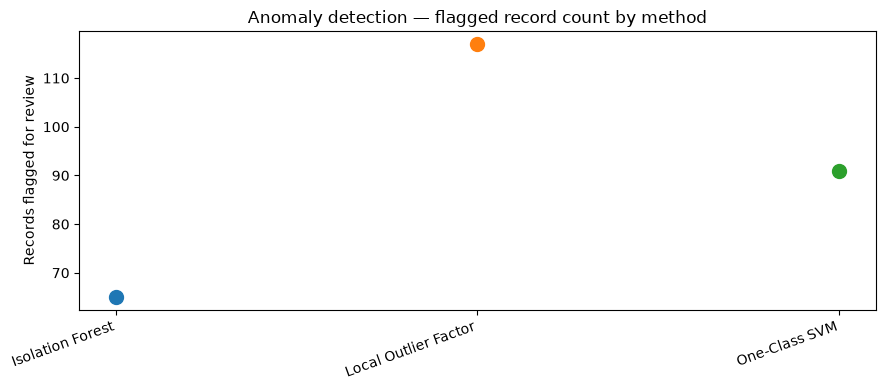

In [12]:
method_names = list(comparison_outputs.keys())
flag_matrix = pd.DataFrame({
    name: comparison_outputs[name]["flags"]
    for name in method_names
}, index=analysis_df.index)

agreement_rows = []
for i, name_a in enumerate(method_names):
    for name_b in method_names[i + 1:]:
        a = flag_matrix[name_a]
        b = flag_matrix[name_b]
        intersection = int((a & b).sum())
        union = int((a | b).sum())
        jaccard = intersection / union if union else 1.0
        agreement_rows.append({
            "method_a": name_a,
            "method_b": name_b,
            "both_flagged": intersection,
            "either_flagged": union,
            "flag_overlap_jaccard": round(jaccard, 3)
        })

agreement = pd.DataFrame(agreement_rows)
display(agreement)

plt.figure(figsize=(9, 4))
for name in method_names:
    plt.plot(
        [name],
        [comparison_outputs[name]["flags"].sum()],
        marker="o",
        markersize=10,
        label=name
    )
plt.ylabel("Records flagged for review")
plt.title("Anomaly detection — flagged record count by method")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Outcome and conclusion

The overlap table shows how often two methods flag the same records. A higher overlap means the methods are more consistent with one another.

If the methods flag different records, that does not automatically mean one is wrong. It means they detect unusual patterns in different ways. Records flagged by multiple methods can be prioritised for manual review, while records flagged by only one method may need a more careful look at their material family and source evidence.

## 13. Create a combined review-priority table

In [13]:
combined_review = analysis_df[
    ["record_id", "product_id", "variant_id",
     "material_category_group", "material_family",
     "manufacturer", "data_status", "recommended_split", *FEATURES]
].copy()

for name in method_names:
    safe_name = name.lower().replace(" ", "_")
    combined_review[f"{safe_name}_review"] = comparison_outputs[name]["flags"]

review_columns = [
    f"{name.lower().replace(' ', '_')}_review"
    for name in method_names
]
combined_review["methods_flagging"] = combined_review[review_columns].sum(axis=1)
combined_review["review_priority"] = np.select(
    [
        combined_review["methods_flagging"] == len(method_names),
        combined_review["methods_flagging"] == 2,
        combined_review["methods_flagging"] == 1
    ],
    ["HIGH — all methods", "MEDIUM — two methods", "CHECK — one method"],
    default="NOT FLAGGED"
)

priority_counts = combined_review["review_priority"].value_counts().to_frame("records")
display(priority_counts)

priority_review_list = (
    combined_review[combined_review["methods_flagging"] > 0]
    .sort_values(["methods_flagging", "material_family"], ascending=[False, True])
)
display(priority_review_list.head(40))

,records
review_priority,
NOT FLAGGED,1590
CHECK — one method,91
MEDIUM — two methods,58
HIGH — all methods,22


,record_id,product_id,variant_id,material_category_group,material_family,manufacturer,data_status,recommended_split,thickness_mm,thermal_resistance_m2K_W,thermal_conductivity_W_mK,isolation_forest_review,local_outlier_factor_review,one-class_svm_review,methods_flagging,review_priority
1474,ML_STORAENSO_CLT_180MM_C5S,STORAENSO_CLT,STORAENSO_CLT_180MM_C5S,D_timber_biobased,CLT,Stora Enso Wood Products,VERIFIED,test,180.0,1.5000,0.120,True,True,True,3,HIGH — all methods
1475,ML_STORAENSO_CLT_200MM_C5S,STORAENSO_CLT,STORAENSO_CLT_200MM_C5S,D_timber_biobased,CLT,Stora Enso Wood Products,VERIFIED,test,200.0,1.6670,0.120,True,True,True,3,HIGH — all methods
1478,ML_STORAENSO_CLT_180MM_C7S,STORAENSO_CLT,STORAENSO_CLT_180MM_C7S,D_timber_biobased,CLT,Stora Enso Wood Products,VERIFIED,test,180.0,1.5000,0.120,True,True,True,3,HIGH — all methods
1479,ML_STORAENSO_CLT_200MM_C7S,STORAENSO_CLT,STORAENSO_CLT_200MM_C7S,D_timber_biobased,CLT,Stora Enso Wood Products,VERIFIED,test,200.0,1.6670,0.120,True,True,True,3,HIGH — all methods
1506,ML_KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR_12_5MM,KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR,KNAUF_AQUAPANEL_CEMENT_BOARD_OUTDOOR_12_5MM,E_boards,cement_board,Knauf AQUAPANEL GmbH & Co. KG,VERIFIED,train,12.5,0.0357,0.350,True,True,True,3,HIGH — all methods
1875,ML_SGUK_GYPROC_SOUNDBLOC_12_5MM,SGUK_GYPROC_SOUNDBLOC,SGUK_GYPROC_SOUNDBLOC_12_5MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0500,0.250,True,True,True,3,HIGH — all methods
1876,ML_SGUK_GYPROC_SOUNDBLOC_15MM,SGUK_GYPROC_SOUNDBLOC,SGUK_GYPROC_SOUNDBLOC_15MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,15.0,0.0600,0.250,True,True,True,3,HIGH — all methods
1877,ML_SGUK_GYPROC_SOUNDBLOC_MR_15MM,SGUK_GYPROC_SOUNDBLOC_MR,SGUK_GYPROC_SOUNDBLOC_MR_15MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,test,15.0,0.0600,0.250,True,True,True,3,HIGH — all methods
1878,ML_SGUK_GYPROC_FIRELINE_12_5MM,SGUK_GYPROC_FIRELINE,SGUK_GYPROC_FIRELINE_12_5MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,12.5,0.0520,0.240,True,True,True,3,HIGH — all methods
1879,ML_SGUK_GYPROC_FIRELINE_15MM,SGUK_GYPROC_FIRELINE,SGUK_GYPROC_FIRELINE_15MM,E_boards,gypsum_board,Saint-Gobain UK – British Gypsum,PARTIALLY_VERIFIED,train,15.0,0.0620,0.240,True,True,True,3,HIGH — all methods


### Outcome and conclusion

This table combines the three methods into one review aid. Records flagged by all three methods receive the highest review priority; records flagged by one method receive a lower priority.

This is only a way to organise manual checks. It is not a confidence score and must not be used to automatically reject or correct a product record.

## 14. Save the multi-method comparison

In [14]:
comparison_path = REPORT_DIR / "anomaly_detection_model_comparison_v1.csv"
agreement_path = REPORT_DIR / "anomaly_detection_method_agreement_v1.csv"
priority_path = REPORT_DIR / "anomaly_detection_combined_review_v1.csv"
comparison_model_path = MODEL_DIR / "anomaly_detection_models_comparison_v1.joblib"

anomaly_comparison.to_csv(comparison_path, index=False)
agreement.to_csv(agreement_path, index=False)
priority_review_list.to_csv(priority_path, index=False)

joblib.dump(
    {name: comparison_outputs[name]["model"] for name in method_names},
    comparison_model_path
)

print("Saved model comparison:", comparison_path)
print("Saved method agreement:", agreement_path)
print("Saved combined review list:", priority_path)
print("Saved fitted models:", comparison_model_path)

Saved model comparison: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_model_comparison_v1.csv
Saved method agreement: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_method_agreement_v1.csv
Saved combined review list: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\anomaly_detection_combined_review_v1.csv
Saved fitted models: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\anomaly_detection\anomaly_detection_models_comparison_v1.joblib


# Final conclusion — Anomaly Detection

The first experiment used Isolation Forest to screen product records for unusual combinations of thickness, thermal resistance and thermal conductivity. We have now extended the analysis by comparing three methods: Isolation Forest, Local Outlier Factor and One-Class SVM.

All methods use the same selected features and training records. A consistent training-score threshold is applied to mark the lowest 3% of training scores for review. This gives us a more structured comparison, but 3% is a screening setting—not the actual percentage of incorrect records.

The comparison table shows how many records each method flags. The agreement analysis shows whether the methods identify the same records. Records flagged by several methods can be prioritised for manual checking, but no algorithmic flag confirms that a product value is wrong.

A major limitation remains: the dataset contains many more insulation records than some other material families. A general anomaly detector may flag a less-represented family because its properties differ from the dominant patterns. Family-specific screening may be worth investigating later.

**Final takeaway:** Comparing multiple anomaly-detection methods gives us a better understanding of how dependent the review list is on the chosen algorithm. The methods should support data-quality investigation, not replace manufacturer documents or engineering checks.

After running this updated notebook, compare the actual flag counts and overlap results. We should decide which method—or combination of methods—is most useful for SpecSynth AI only after reviewing those results.